# Descriptive Analytics

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data_charge = pd.read_pickle("../data/data_charge_prep.pkl")

In [3]:
# Split the DataFrame according to the two sites
site1 = data_charge[data_charge["siteID"] == 1]
site2 = data_charge[data_charge["siteID"] == 2]

# Print the start and end of the timeframes
print(f"Site 1 Timespan: {site1.connectionTime.min()} - {site1.disconnectTime.max()}")
print(f"Site 2 Timespan: {site2.connectionTime.min()} - {site2.disconnectTime.max()}")
print("")

# Get the number of stations for each site
print(f"Number of stations for Site 1: {site1.stationID.nunique()}")
print(f"Number of stations for Site 2: {site2.stationID.nunique()}")

Site 1 Timespan: 2018-09-05 03:04:13+00:00 - 2021-09-14 06:46:28+00:00
Site 2 Timespan: 2018-04-25 05:45:10+00:00 - 2021-09-13 19:05:10+00:00

Number of stations for Site 1: 52
Number of stations for Site 2: 55


In [4]:
print(f"Samples for site 1: {len(data_charge[data_charge['siteID']==1])}")
print(f"Samples for site 2: {len(data_charge[data_charge['siteID']==2])}")

Samples for site 1: 32830
Samples for site 2: 30991


# Note: We have 10% more samples for site 1, than for site 2. Our model might be better to predict the values for site 1.

### Temporal Patterns and Seasonality
 Demonstrate how the number of charging events varies during
 the day, the week, and between seasons. What patterns can you observe, and how do you explain
 them?

#### Pattern during the day

Discuss: eventuell nicht nur auf connectionTime sondern gesamten Ladezyklus?

In [5]:
# data_charge[data_charge["siteID"]==2]

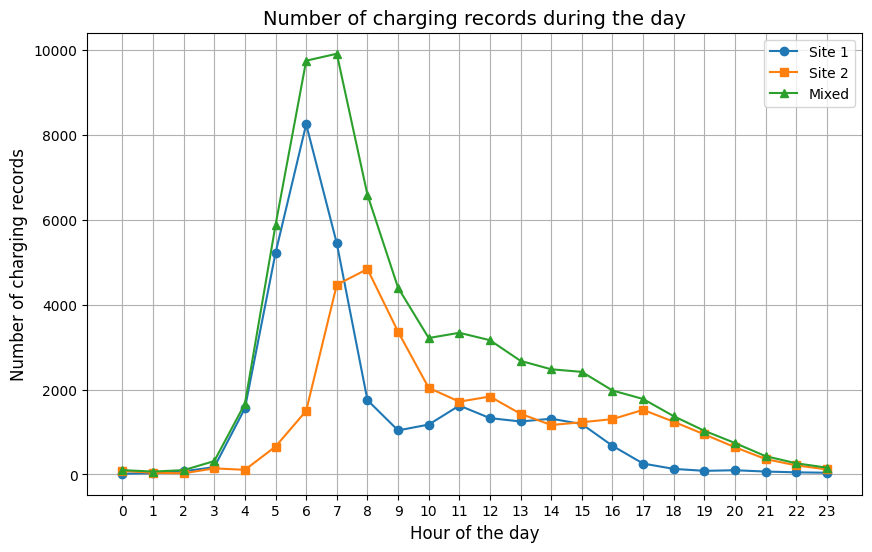

In [6]:
data_charge["hour"] = data_charge["connectionTime"].dt.hour
charging_by_hour_one = data_charge[data_charge["siteID"] == 1]["hour"].value_counts().sort_index()
charging_by_hour_two = data_charge[data_charge["siteID"] == 2]["hour"].value_counts().sort_index()
charging_by_hour_mixed = data_charge["hour"].value_counts().sort_index()

hours_list = [i for i in range(0, 24)]

plt.figure(figsize=(10, 6))
plt.plot(hours_list, charging_by_hour_one, label="Site 1", marker="o")
plt.plot(hours_list, charging_by_hour_two, label="Site 2", marker="s")
plt.plot(hours_list, charging_by_hour_mixed, label="Mixed", marker="^")

plt.title("Number of charging records during the day", fontsize=14)
plt.xlabel("Hour of the day", fontsize=12)
plt.xticks(range(0, 24))
plt.ylabel("Number of charging records", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

In [7]:
# # Backup
# charging_by_hour = data_charge["hour"].value_counts().sort_index()
# charging_by_hour_2 = charging_by_hour+2000

# # Plot
# plt.figure(figsize=(10, 6))
# plt.plot(charging_by_hour.index, charging_by_hour.values, charging_by_hour_2.values, marker="o")
# plt.title("Number of charging records during the day", fontsize=14)
# plt.xlabel("Hour of the day", fontsize=12)
# plt.ylabel("Number of charging records", fontsize=12)
# plt.grid(True)
# plt.xticks(range(0, 24))
# plt.show()

In [8]:
data_charge.columns

Index(['Unnamed: 0', 'id', 'connectionTime', 'disconnectTime',
       'doneChargingTime', 'kWhDelivered', 'sessionID', 'siteID', 'spaceID',
       'stationID', 'timezone', 'userID', 'userInputs', 'endChargingTime',
       'chargingDurationMin', 'blockingDurationMin', 'hour'],
      dtype='object')

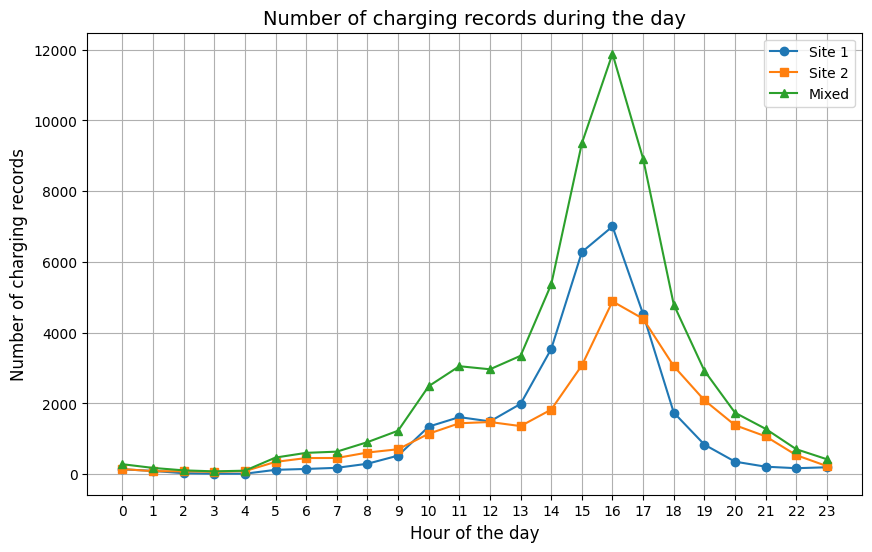

In [9]:
# Disconnect Count
data_charge["hour"] = data_charge["disconnectTime"].dt.hour
charging_by_hour_one = data_charge[data_charge["siteID"] == 1]["hour"].value_counts().sort_index()
charging_by_hour_two = data_charge[data_charge["siteID"] == 2]["hour"].value_counts().sort_index()
charging_by_hour_mixed = data_charge["hour"].value_counts().sort_index()

hours_list = [i for i in range(0, 24)]

plt.figure(figsize=(10, 6))
plt.plot(hours_list, charging_by_hour_one, label="Site 1", marker="o")
plt.plot(hours_list, charging_by_hour_two, label="Site 2", marker="s")
plt.plot(hours_list, charging_by_hour_mixed, label="Mixed", marker="^")

plt.title("Number of charging records during the day", fontsize=14)
plt.xlabel("Hour of the day", fontsize=12)
plt.xticks(range(0, 24))
plt.ylabel("Number of charging records", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

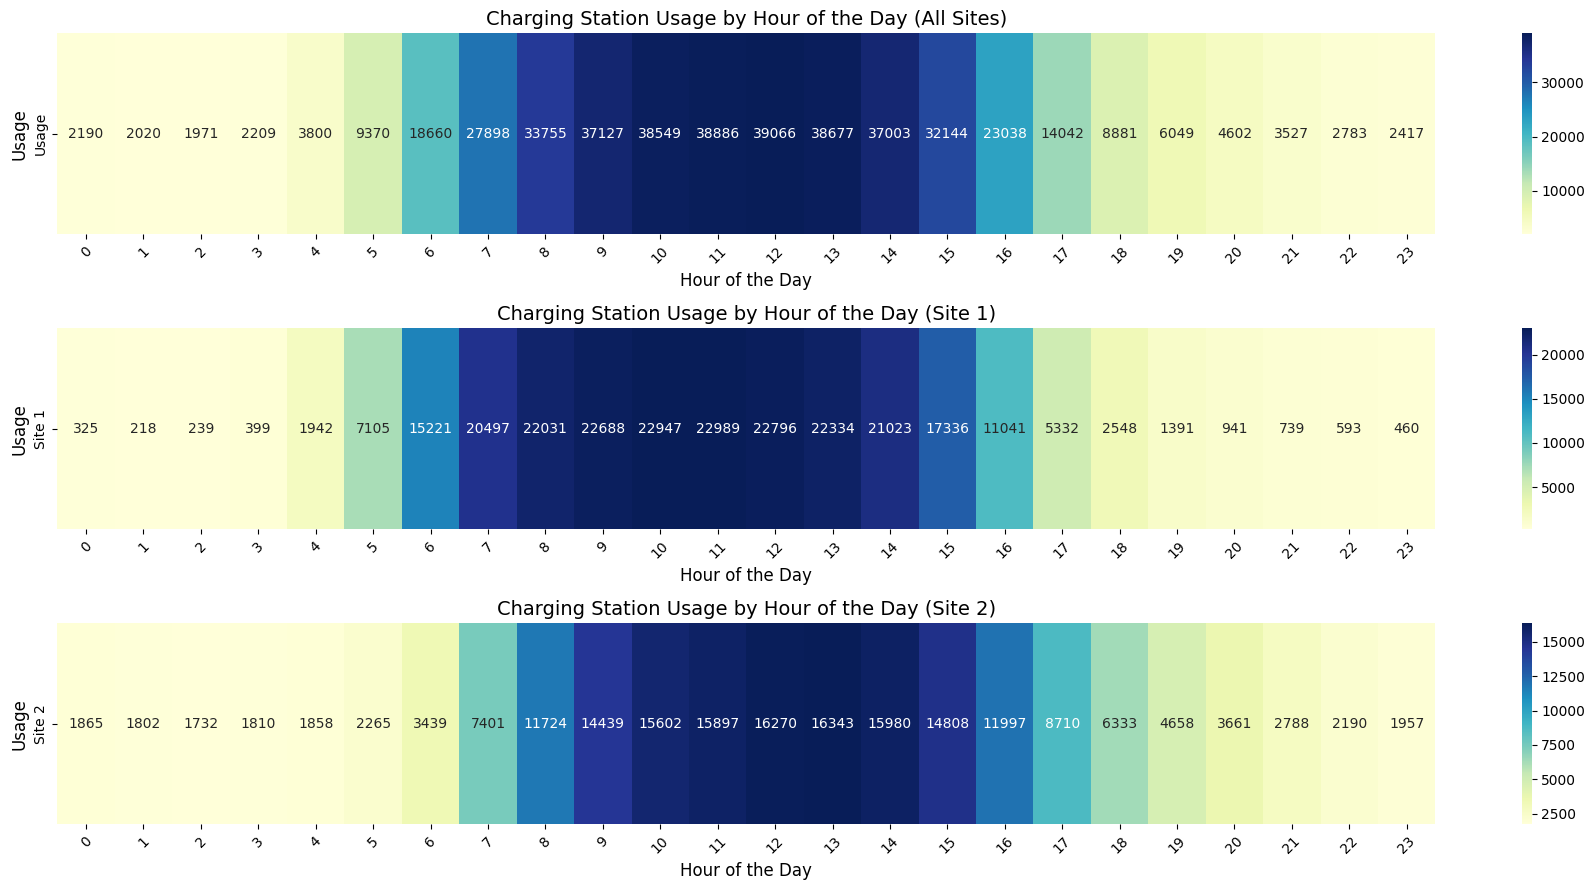

In [10]:
import seaborn as sns


data_charge["connectionTime"] = pd.to_datetime(data_charge["connectionTime"])
data_charge["disconnectTime"] = pd.to_datetime(data_charge["disconnectTime"])


def get_active_hours(row):
    active_hours = pd.date_range(row["connectionTime"], row["disconnectTime"], freq="H").hour
    return active_hours


data_charge["active_hours"] = data_charge.apply(get_active_hours, axis=1)

active_hours_flat = [hour for hours in data_charge["active_hours"] for hour in hours]

df_active_hours = pd.DataFrame(active_hours_flat, columns=["Hour"])
df_active_hours["Count"] = 1

usage_by_hour = df_active_hours.groupby("Hour").size()

data_charge_site_1 = data_charge[data_charge["siteID"] == 1]
data_charge_site_2 = data_charge[data_charge["siteID"] == 2]

active_hours_site_1 = [hour for hours in data_charge_site_1["active_hours"] for hour in hours]
active_hours_site_2 = [hour for hours in data_charge_site_2["active_hours"] for hour in hours]

df_active_hours_site_1 = pd.DataFrame(active_hours_site_1, columns=["Hour"])
df_active_hours_site_1["Count"] = 1

df_active_hours_site_2 = pd.DataFrame(active_hours_site_2, columns=["Hour"])
df_active_hours_site_2["Count"] = 1

usage_by_hour_site_1 = df_active_hours_site_1.groupby("Hour").size()
usage_by_hour_site_2 = df_active_hours_site_2.groupby("Hour").size()

heatmap_data = usage_by_hour.values.reshape(1, -1)

heatmap_data_site_1 = usage_by_hour_site_1.values.reshape(1, -1)

heatmap_data_site_2 = usage_by_hour_site_2.values.reshape(1, -1)


plt.figure(figsize=(18, 9))

plt.subplot(3, 1, 1)
sns.heatmap(
    heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt="d",
    xticklabels=usage_by_hour.index,
    yticklabels=["Usage"],
)
plt.title("Charging Station Usage by Hour of the Day (All Sites)", fontsize=14)
plt.xlabel("Hour of the Day", fontsize=12)
plt.ylabel("Usage", fontsize=12)
plt.xticks(rotation=45)

plt.subplot(3, 1, 2)
sns.heatmap(
    heatmap_data_site_1,
    cmap="YlGnBu",
    annot=True,
    fmt="d",
    xticklabels=usage_by_hour_site_1.index,
    yticklabels=["Site 1"],
)
plt.title("Charging Station Usage by Hour of the Day (Site 1)", fontsize=14)
plt.xlabel("Hour of the Day", fontsize=12)
plt.ylabel("Usage", fontsize=12)
plt.xticks(rotation=45)

plt.subplot(3, 1, 3)
sns.heatmap(
    heatmap_data_site_2,
    cmap="YlGnBu",
    annot=True,
    fmt="d",
    xticklabels=usage_by_hour_site_2.index,
    yticklabels=["Site 2"],
)
plt.title("Charging Station Usage by Hour of the Day (Site 2)", fontsize=14)
plt.xlabel("Hour of the Day", fontsize=12)
plt.ylabel("Usage", fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


#### Pattern during the day

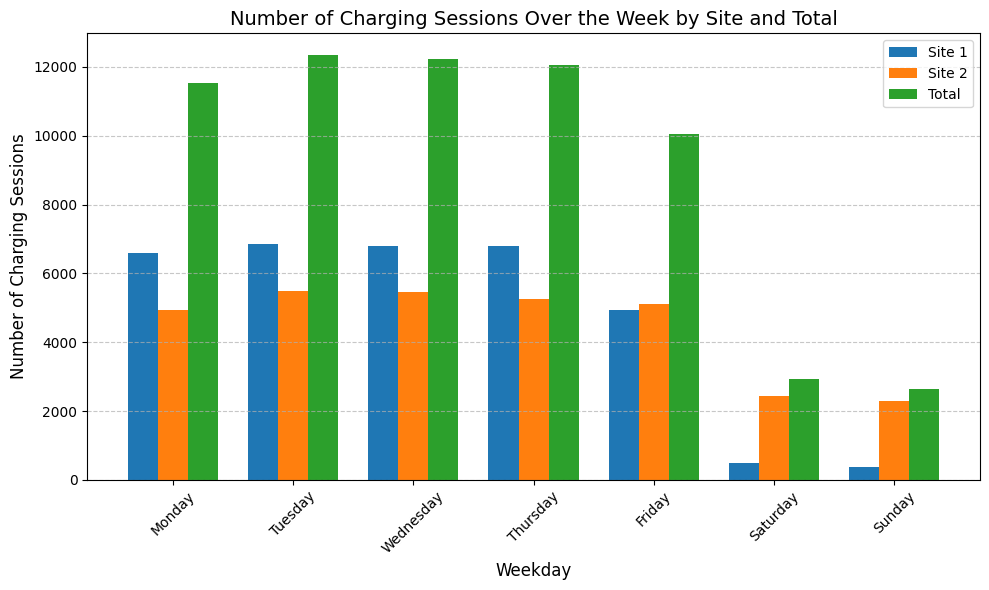

In [11]:
# Wochentag berechnen
data_charge["weekday"] = data_charge["connectionTime"].dt.dayofweek

# Wertanzahl der Wochentage pro Site berechnen
charging_by_weekday_site1 = (
    data_charge[data_charge["siteID"] == 1]["weekday"].value_counts().sort_index()
)
charging_by_weekday_site2 = (
    data_charge[data_charge["siteID"] == 2]["weekday"].value_counts().sort_index()
)
charging_by_weekday_total = data_charge["weekday"].value_counts().sort_index()

# Labels für die Wochentage
weekday_labels = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_indices = list(range(7))

# Plot erstellen
plt.figure(figsize=(10, 6))
bar_width = 0.25  # Breite der Balken

# Balken für Site 1 (links)
plt.bar(
    [i - bar_width for i in weekday_indices],
    charging_by_weekday_site1,
    width=bar_width,
    label="Site 1",
)

# Balken für Site 2 (zentral)
plt.bar(weekday_indices, charging_by_weekday_site2, width=bar_width, label="Site 2")

# Balken für Gesamtzahl (rechts)
plt.bar(
    [i + bar_width for i in weekday_indices],
    charging_by_weekday_total,
    width=bar_width,
    label="Total",
)

# Titel und Achsenbeschriftungen
plt.title("Number of Charging Sessions Over the Week by Site and Total", fontsize=14)
plt.xlabel("Weekday", fontsize=12)
plt.ylabel("Number of Charging Sessions", fontsize=12)
plt.xticks(weekday_indices, weekday_labels, rotation=45)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

#### Seasonal Patterns

Hint: Normalisierung noch sinnvoll (es gibt mehr Sommer als Wintermonate im Datensatz)

C:\Users\Reintjes\AppData\Local\Temp\ipykernel_11708\2594480034.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  data_charge["month_year"] = data_charge["connectionTime"].dt.to_period("M")


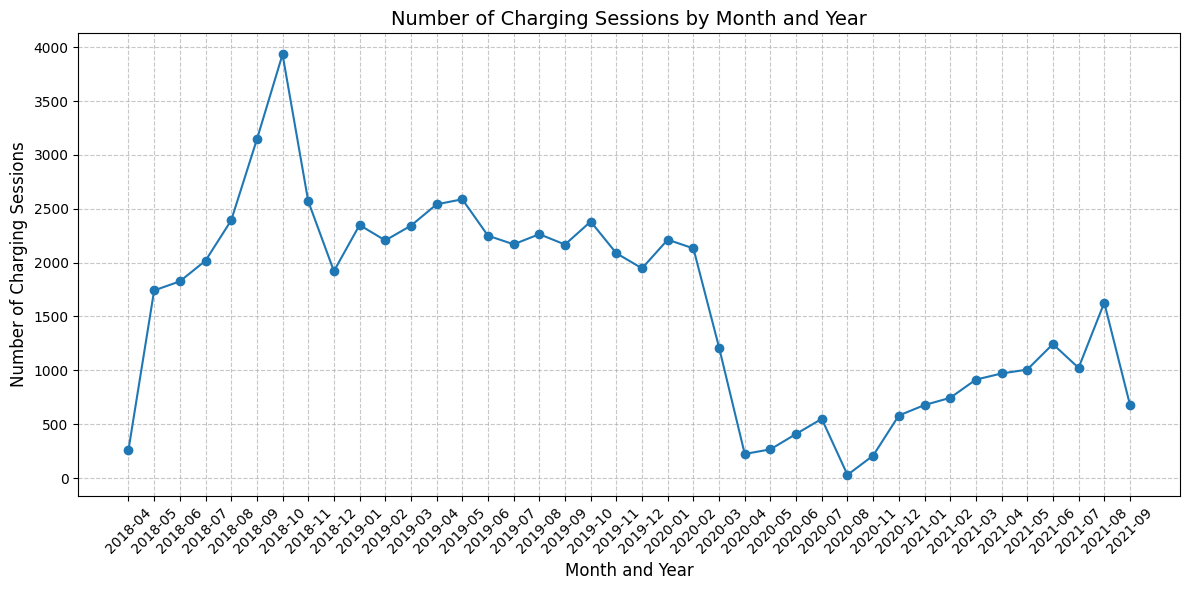

In [12]:
data_charge["month_year"] = data_charge["connectionTime"].dt.to_period("M")
charging_by_month_year = data_charge["month_year"].value_counts().sort_index()

# plot
plt.figure(figsize=(12, 6))
plt.plot(charging_by_month_year.index.astype(str), charging_by_month_year.values, marker="o")
plt.title("Number of Charging Sessions by Month and Year", fontsize=14)
plt.xlabel("Month and Year", fontsize=12)
plt.ylabel("Number of Charging Sessions", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

We can see that the start of the charging session recording is in April 2018 and ends in September 2021, which is why not every month occurs equally often and we therefore have to normalise. We also see a gap between 08/2020 and 11/2020.

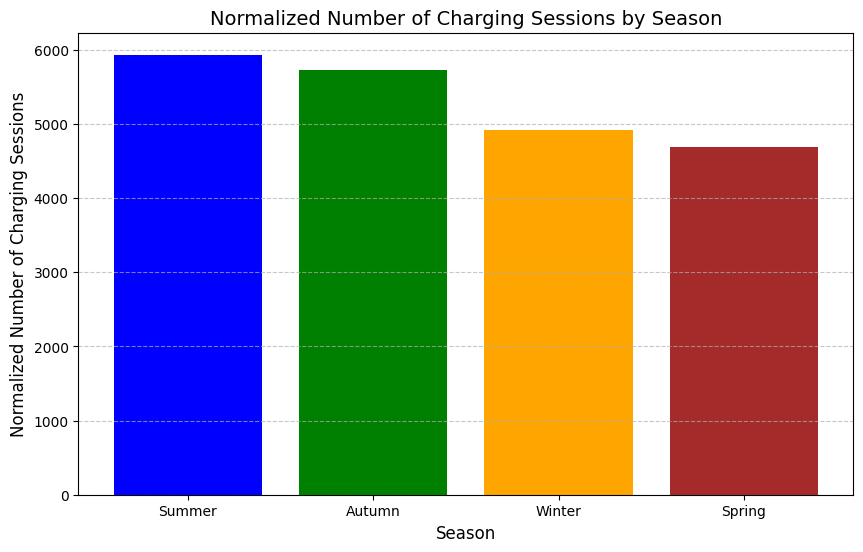

In [13]:
import pandas as pd
import matplotlib.pyplot as plt


# Funktion zur Bestimmung der Saison
def get_season(date):
    month = date.month
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    elif month in [9, 10, 11]:
        return "Autumn"


data_charge["season"] = data_charge["connectionTime"].apply(get_season)

charging_by_season = data_charge["season"].value_counts()


season_month_count = {
    "Winter": len(
        data_charge[data_charge["season"] == "Winter"]["connectionTime"].dt.month.unique()
    ),
    "Spring": len(
        data_charge[data_charge["season"] == "Spring"]["connectionTime"].dt.month.unique()
    ),
    "Summer": len(
        data_charge[data_charge["season"] == "Summer"]["connectionTime"].dt.month.unique()
    ),
    "Autumn": len(
        data_charge[data_charge["season"] == "Autumn"]["connectionTime"].dt.month.unique()
    ),
}

normalized_charging_by_season = charging_by_season / [
    season_month_count[season] for season in charging_by_season.index
]

# Plot
plt.figure(figsize=(10, 6))
plt.bar(
    normalized_charging_by_season.index,
    normalized_charging_by_season.values,
    color=["blue", "green", "orange", "brown"],
)
plt.title("Normalized Number of Charging Sessions by Season", fontsize=14)
plt.xlabel("Season", fontsize=12)
plt.ylabel("Normalized Number of Charging Sessions", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

C:\Users\Reintjes\AppData\Local\Temp\ipykernel_11708\3931265292.py:45: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '2790.6666666666665' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  normalized_charging_by_season_site.loc[season] = (
C:\Users\Reintjes\AppData\Local\Temp\ipykernel_11708\3931265292.py:45: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '2933.6666666666665' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  normalized_charging_by_season_site.loc[season] = (


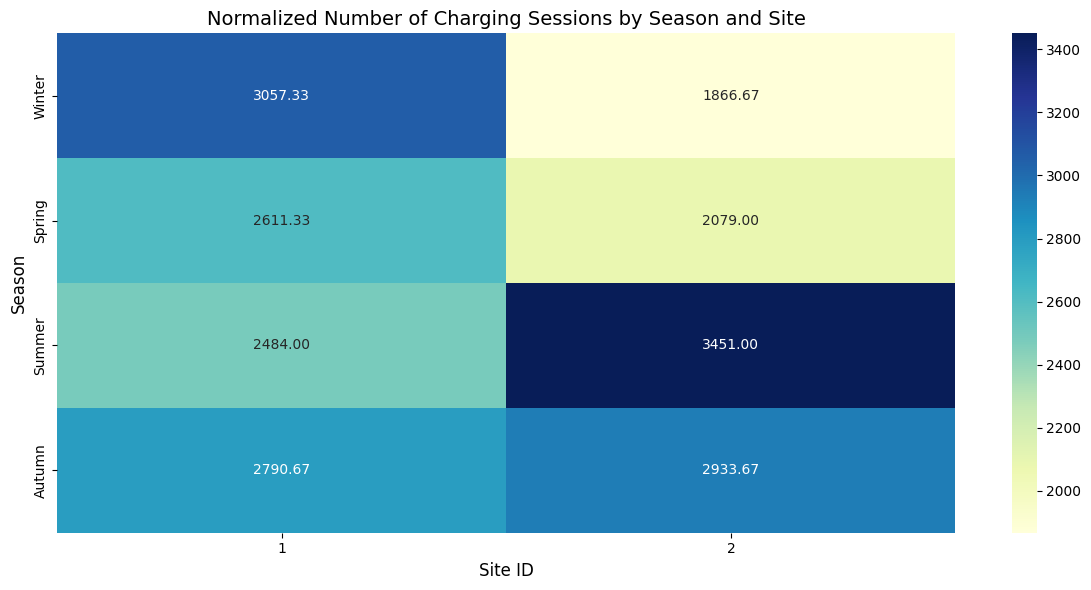

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Funktion zur Bestimmung der Saison
def get_season(date):
    month = date.month
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    elif month in [9, 10, 11]:
        return "Autumn"


# Saison-Spalte erstellen
data_charge["season"] = data_charge["connectionTime"].apply(get_season)

# Berechnen der Monate, die für jede Saison im Datensatz vorhanden sind
season_month_count = {
    "Winter": len(
        data_charge[data_charge["season"] == "Winter"]["connectionTime"].dt.month.unique()
    ),
    "Spring": len(
        data_charge[data_charge["season"] == "Spring"]["connectionTime"].dt.month.unique()
    ),
    "Summer": len(
        data_charge[data_charge["season"] == "Summer"]["connectionTime"].dt.month.unique()
    ),
    "Autumn": len(
        data_charge[data_charge["season"] == "Autumn"]["connectionTime"].dt.month.unique()
    ),
}

# Gruppieren nach Saison und Site
charging_by_season_site = data_charge.groupby(["season", "siteID"]).size().unstack(fill_value=0)

# Normalisierung der Anzahl der Ladesitzungen, indem durch die tatsächliche Anzahl der Monate in jeder Saison geteilt wird
normalized_charging_by_season_site = charging_by_season_site.copy()

for season in charging_by_season_site.index:
    normalized_charging_by_season_site.loc[season] = (
        charging_by_season_site.loc[season] / season_month_count[season]
    )

# Reihenfolge der Saisonen nach "Winter", "Spring", "Summer", "Autumn" sortieren
season_order = ["Winter", "Spring", "Summer", "Autumn"]
normalized_charging_by_season_site = normalized_charging_by_season_site.reindex(season_order)

# Plot
plt.figure(figsize=(12, 6))

# Erstellen der Heatmap für alle Sites und Saisonen
sns.heatmap(normalized_charging_by_season_site, cmap="YlGnBu", annot=True, fmt=".2f", cbar=True)

plt.title("Normalized Number of Charging Sessions by Season and Site", fontsize=14)
plt.xlabel("Site ID", fontsize=12)
plt.ylabel("Season", fontsize=12)
plt.tight_layout()
plt.show()

1. kWh Delivered (Proxy for revenue and safed CO2-emissions) (Sum(kWh))
2. Utilization rate per hour (The utilization rate indicates how often charging stations are in use compared to how often they are available) (vielleicht auch Abweichung von Stunde,Wochentag,Season) -> zu viel/wenig charging stations
3. Charge time ratio (chargetime/connection time) -> Accessabilty and efficient use of the stations -> maybe increase charging stations or punish blocking time by still a bit charging money while blocking


Source: @article{article,
author = {Helmus, Jurjen and van den Hoed, Robert},
year = {2016},
month = {12},
pages = {733-741},
title = {Key Performance Indicators of Charging infrastructure},
volume = {8},
journal = {World Electric Vehicle Journal},
doi = {10.3390/wevj8040733}
}

## Indentify site
**Task**: Site Characteristics: The hub operator provided you with the data set, but has seemed to forget which site was supplying which data... Can you find out which of the two sites is the public one?
Try to combine data understanding from previous descriptive analytics with domain knowledge (business understanding) of how private vs. public charging hubs might differ in operation. Explain your line of thought!

# The following descriptions can be derived from the previous time patterns and the analysis of seasonality:
- Charging usage during the day is very different: at site 1, most EVs are connected around 6/7am, while at site 2 most connections start at 8/9am. At site 2, however, the peak connection time is not as high as at site 1, the connection time is much more spread throughout the day. In addition, the use of the charging station at night is more likely at site 2.
- During the week, the number of charging sessions at the individual sites also varies: while site 1 is used most frequently during the week and almost not at all at weekends, site 2 is in use throughout the week. Usage at the weekend is also lower, but not as strong as at site 1.
- Similar to usage during the day and week, there are also differences in usage by season: site 1 is used about equally throughout the year. Site 2, on the other hand, shows a more uneven distribution: it is used most of the time in summer, then in fall, then in spring and then in winter.


# Interpretation based on the Descriptions and Domain Knowledge: Which site is public and which is private?

## 1st daytime usage pattern
- **Site 1:** Most connections start at 6/7am, indicating regular working hours. This indicates that the users are employees of a company who come to work early and charge their vehicles during working hours.
- **Site 2:** Connections start at 8/9am and are spread throughout the day, with additional usage at night. This suits a public site such as a university, which is used by both internal users (students and staff) and external people, e.g. for visits, events or as a general parking lot.

**Conclusion:**  
- **Site 1:** Private (company)  
- **Site 2:** Public (university)  

---

## 2nd weekly usage pattern
- **Site 1:** High usage during the week, almost no usage at weekends. This corresponds to the typical use of a private site, as companies usually only operate on weekdays and are closed at weekends.
- **Site 2:** Usage is spread throughout the week, with a slight decrease at weekends. Universities also have activity at weekends (e.g. by students, external visitors or events), but to a lesser extent than during the week.

**Conclusion:**  
- **Site 1:** Private (companies)  
- **Site 2:** Public (university)  

---

## 3. seasonal use
- **Site 1:** Consistent use throughout the year. This suits a private site, as the presence of a company's employees does not depend heavily on the time of year.
- **Site 2:** Usage fluctuates seasonally, with peaks in summer and a decline in winter. This fits with a public site such as a university, which is subject to seasonal fluctuations (semester times, vacations) and attracts more external visitors in summer, e.g. for events or leisure activities on campus.

**Conclusion:**  
- **Site 1:** Private (company)  
- **Site 2:** Public (university)  

---


To strengthen our conclusion, lets analyze

        count        mean         std  min      median          max
siteID                                                             
1       32830  163.872407  179.631971  0.0  110.758333  4609.066667
2       30991  159.890473  273.027015  0.0   53.533333  9367.283333


<Figure size 1000x600 with 0 Axes>

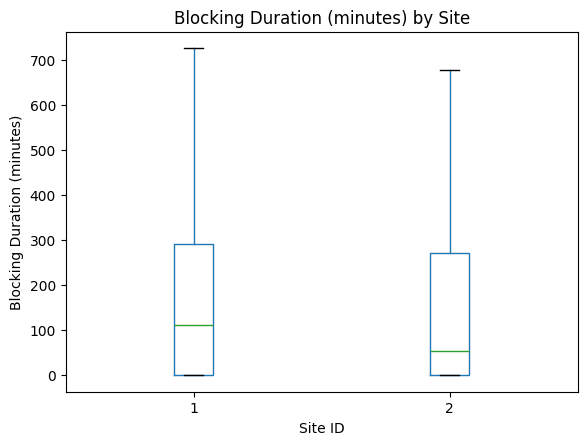

In [ ]:
blocking_by_site = data_charge.groupby('siteID')['blockingDurationMin'].agg(['count', 'mean', 'std', 'min', 'median', 'max'])
#Describe the count, mean, std, min, median and max of the blockingDuration in Min of both sites
print(blocking_by_site)

# Visualize blockingDurationMin for each site
plt.figure(figsize=(10, 6))
data_charge.boxplot(column='blockingDurationMin', by='siteID', grid=False, showfliers=False)
plt.title('Blocking Duration (minutes) by Site')
plt.suptitle('')  # Remove the default matplotlib title
plt.xlabel('Site ID')
plt.ylabel('Blocking Duration (minutes)')
plt.show()

## Median (typical blocking duration)

**Site 1**: 110.76 minutes - Typical for a private site where employees charge their vehicles for the duration of their work, which most of the time is longer than the charging time, resulting in a longer blocking duration time than at a public site.

**Site 2**: 53.53 minutes - The median is significantly lower. This could indicate many short-term uses by external persons or students who only charge for lectures or short stays, for example.

## Distribution of blocking duration (standard deviation)

**Site 1**: 179.63 minutes - The dispersion is lower, which indicates more even loading times, typically for a fixed group of users (e.g. employees of a company).

**Site 2:** 273.03 minutes - The significantly higher dispersion indicates a public site with a mixed user base and variable loading behavior

In [19]:
charging_records_with_user = data_charge.groupby('siteID').apply(
    lambda group: group['userID'].notnull().sum()
)

total_records_per_site = data_charge.groupby('siteID').size()
percentage_with_user = (charging_records_with_user / total_records_per_site) * 100

result = pd.DataFrame({
    'Total Records': total_records_per_site,
    'Records with Users': charging_records_with_user,
    'Percentage with Users': percentage_with_user
}).reset_index()

print(result)


   siteID  Total Records  Records with Users  Percentage with Users
0       1          32830               30668              93.414560
1       2          30991               16223              52.347456


**Site 1** (93.41%):
A very high proportion of charging sessions have a registered user. This indicates controlled, registration-based use, as is typically the case at a private site (company) where the charging infrastructure is primarily used by employees.

**Site 2** (52.35%):
The proportion of charging sessions with a deposited user is significantly lower. This indicates less controlled or publicly accessible use, as might occur at a public site (university). Visitors or unregistered users could use the charging infrastructure here without being recorded as a specific user.

## Overall conclusion
The patterns in daily, weekly and seasonal use as well as the potential external use suggest that:  
- **Site 1** is the **private site** (company), as early peak times (6/7am), high weekday usage, minimal weekend activity, consistent year-round usage, longer blocking durations, and 93.41% registered users indicate controlled, employee-driven usage  
- **Site 2** is the **public site** (university), as spread-out connection times (8/9am), week-long usage, seasonal fluctuations, shorter blocking durations, and 52.35% registered users suggest diverse, public access.

